# Proyecto Final

## Cuantización de Imágenes

Este ejercicio contiene:

- Exploración visual inicial 
- Preprocesamiento
- Reducción del espacio de colores
- Cuantización mediante clustering
- Reconstrucción de imágenes
- Evaluación mediante MSE
- Análisis comparativo
- Conclusiones y mejoras

## 1. Importaciones y configuración inicial

Carga de todas las imágenes y mostrarlas 

Imágenes encontradas: 8
- Bosch.jpg
- Boticelli.jpg
- Dali.jpg
- Monet.jpg
- Picaso.jpg
- VanGogh.jpg
- Velazquez.jpg
- Vermeer.jpg


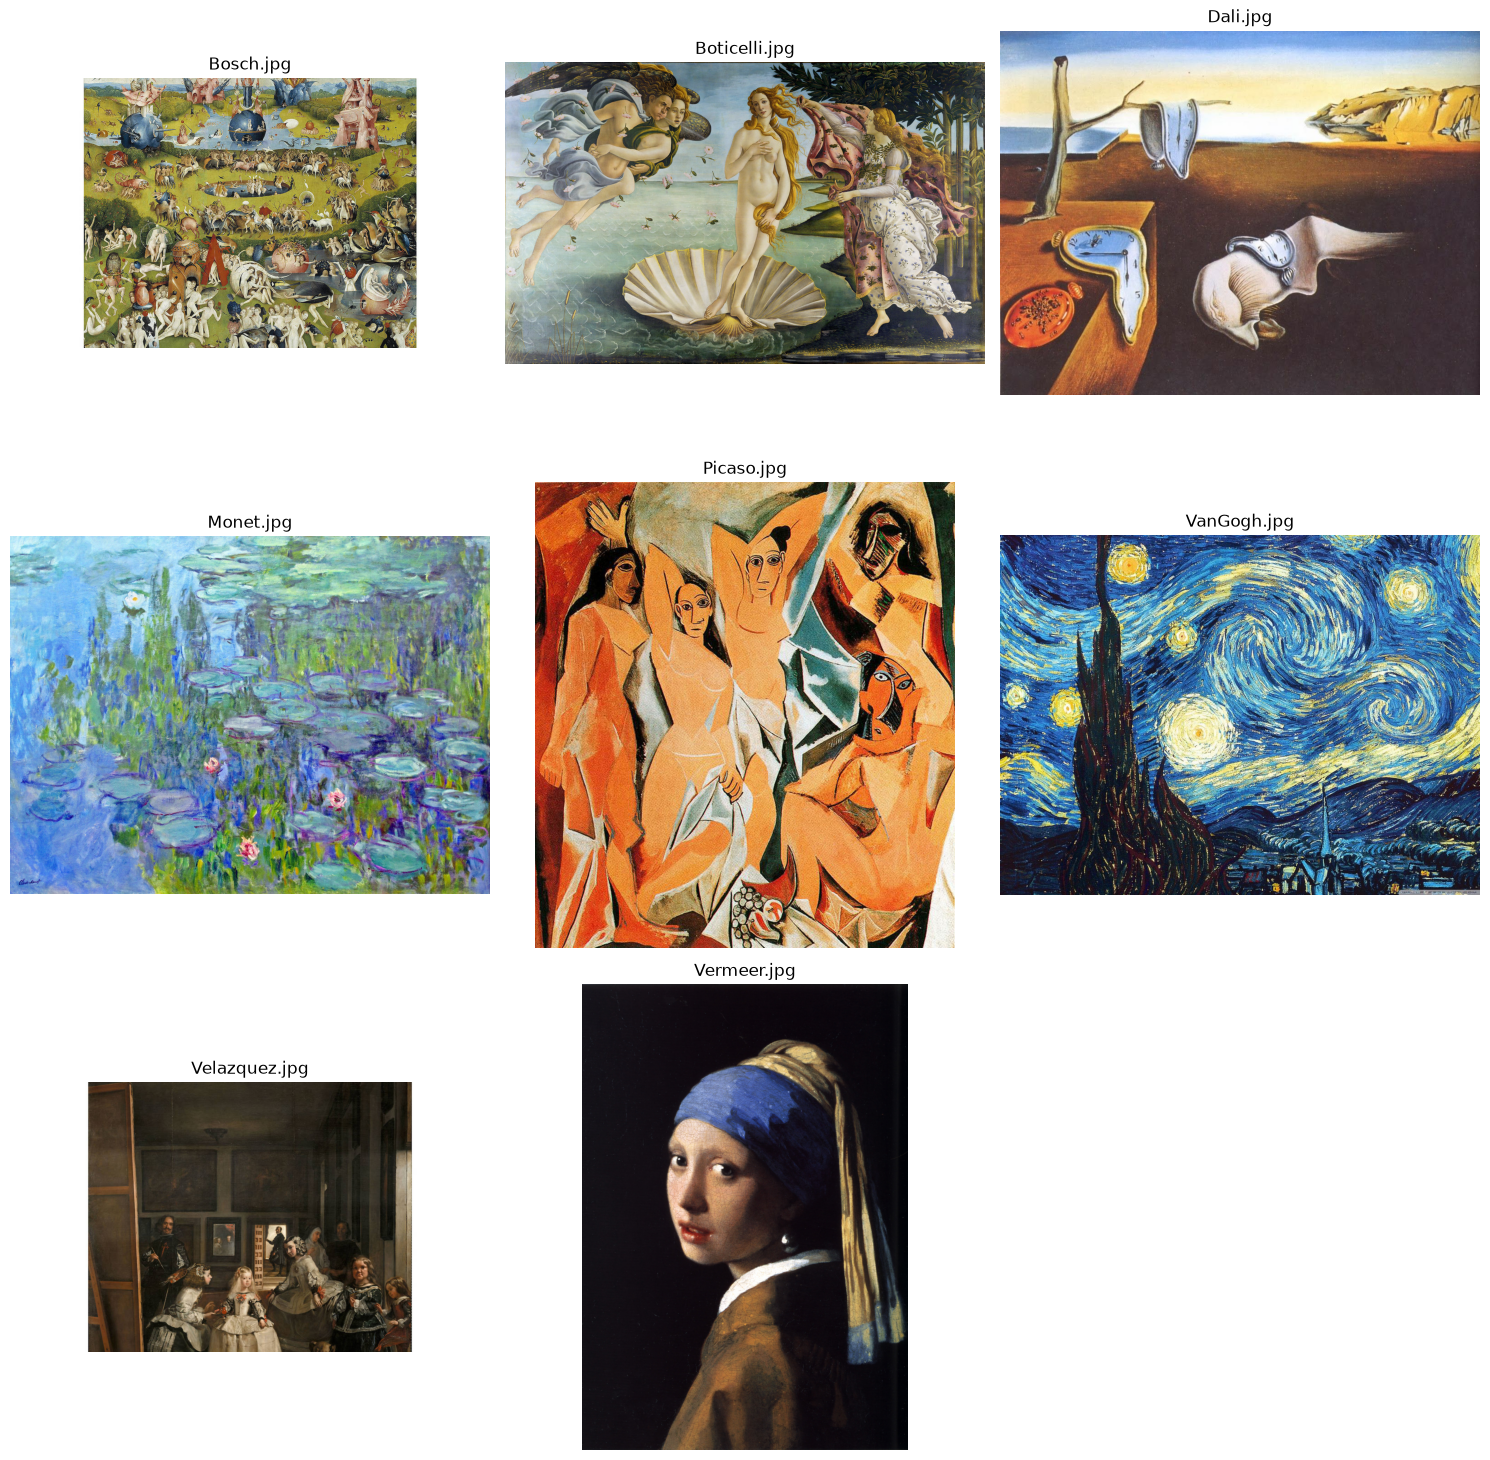

In [44]:
import glob
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os
from sklearn.metrics import pairwise_distances_argmin

%matplotlib inline

# Buscar imágenes .jpg y .png en la misma carpeta
paths = sorted(glob.glob("./*.jpg") + glob.glob("./*.png"))

print("Imágenes encontradas:", len(paths))
for p in paths:
    print("-", os.path.basename(p))

# Mostrar todas las imágenes en una cuadrícula
n = len(paths)
cols = 3
rows = int(np.ceil(n / cols))

plt.figure(figsize=(15, 5 * rows))

for i, ruta in enumerate(paths):
    img = Image.open(ruta).convert("RGB")  
    img_np = np.array(img)

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img_np)
    plt.title(os.path.basename(ruta))
    plt.axis("off")

plt.tight_layout()
plt.show()


## 2. Cuantizar exactamente K colores

Función de cuantización 



In [45]:
def cuantizar_exact_k(img_np, k, method="kmeans", sample_size=20000, batch_size=200000, random_state=0):
    """
    img_np: numpy array HxWx3 (uint8 o similar)
    k: número exacto de colores (clusters)
    method: "kmeans" o "agglomerative"
    sample_size: cantidad de pixeles para entrenar el modelo
    batch_size: cantidad de pixeles para asignar por bloque (evita MemoryError)
    """
    pixels = img_np.reshape(-1, 3).astype(np.float64)  # usar float64 para cómputos
    n_pixels = len(pixels)

    # Submuestreo aleatorio para entrenar 
    if n_pixels > sample_size:
        idx = np.random.choice(n_pixels, sample_size, replace=False)
        sample = pixels[idx]
    else:
        sample = pixels

    # Crear modelo 
    if method.lower().startswith("k"):
        modelo = KMeans(n_clusters=k, random_state=random_state)
    elif method.lower().startswith("a"):
        modelo = AgglomerativeClustering(n_clusters=k)
    else:
        raise ValueError("method debe ser 'kmeans' o 'agglomerative'")

    # Ajustar en la muestra 
    labels_sample = modelo.fit_predict(sample)

    # Obtener centroides (centers) 
    if hasattr(modelo, "cluster_centers_"):
        centers = modelo.cluster_centers_.astype(np.float64)
    else:
        # calcular centroides a partir de la muestra y sus etiquetas
        centers = []
        for i in range(k):
            cluster_pixels = sample[labels_sample == i]
            if len(cluster_pixels) == 0:
                # si algún cluster quedó vacío, asignar un color aleatorio de la muestra
                centers.append(sample[np.random.randint(len(sample))])
            else:
                centers.append(cluster_pixels.mean(axis=0))
        centers = np.array(centers).astype(np.float64)

    # Asignación de todos los pixeles por bloques para no agotar memoria
    labels_full = np.empty(n_pixels, dtype=np.int32)
    for start in range(0, n_pixels, batch_size):
        batch = pixels[start:start+batch_size]
        labels_full[start:start+len(batch)] = pairwise_distances_argmin(batch, centers)

    # Reconstruir imagen con centros 
    centers_uint8 = np.clip(centers, 0, 255).astype(np.uint8)
    reconstruida = centers_uint8[labels_full].reshape(img_np.shape)

    # MSE (error de reconstrucción)
    mse = mean_squared_error(pixels, centers[labels_full])

    return reconstruida, mse, centers_uint8


## 3. Probar diferentes números de colores

Procesando: Bosch.jpg
MSE = 214.95


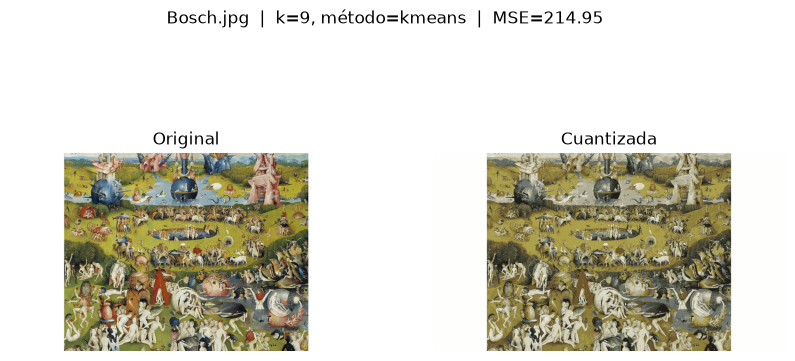

Procesando: Boticelli.jpg
MSE = 215.50


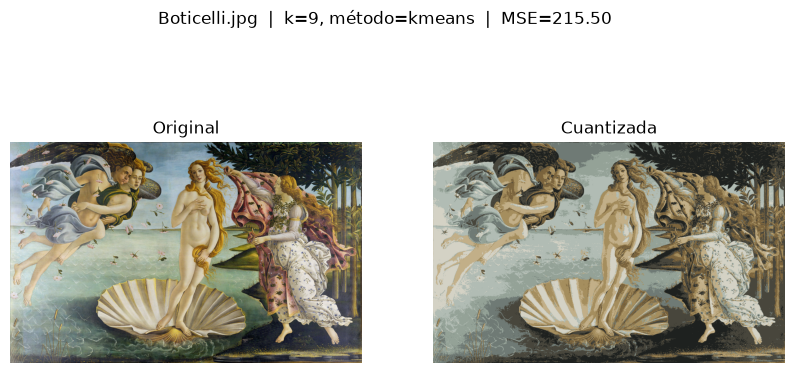

Procesando: Dali.jpg
MSE = 184.19


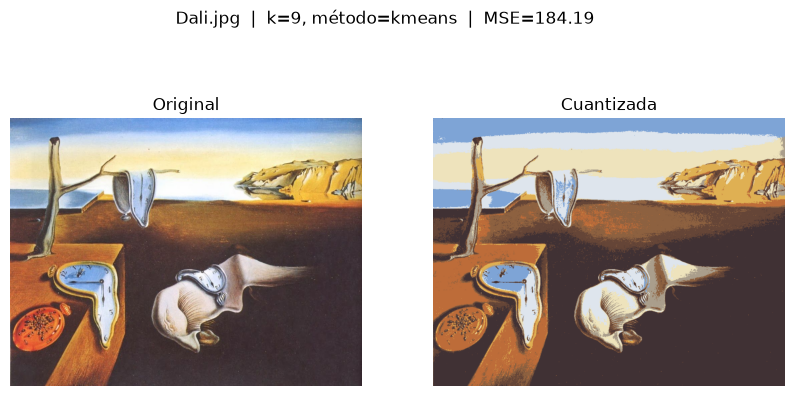

Procesando: Monet.jpg
MSE = 326.97


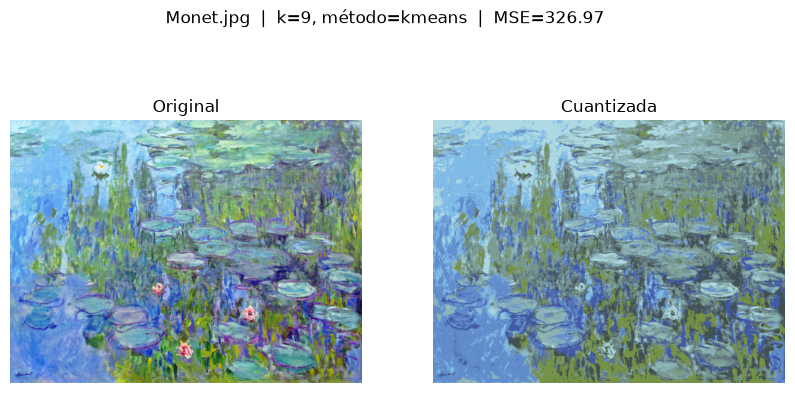

Procesando: Picaso.jpg
MSE = 304.47


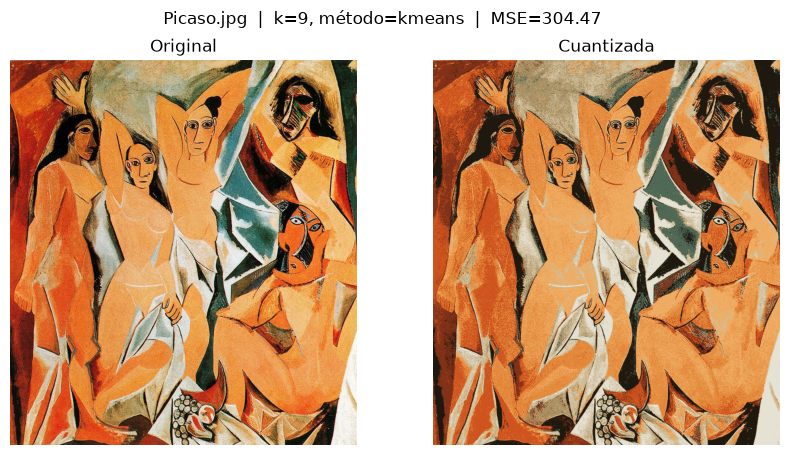

Procesando: VanGogh.jpg
MSE = 327.98


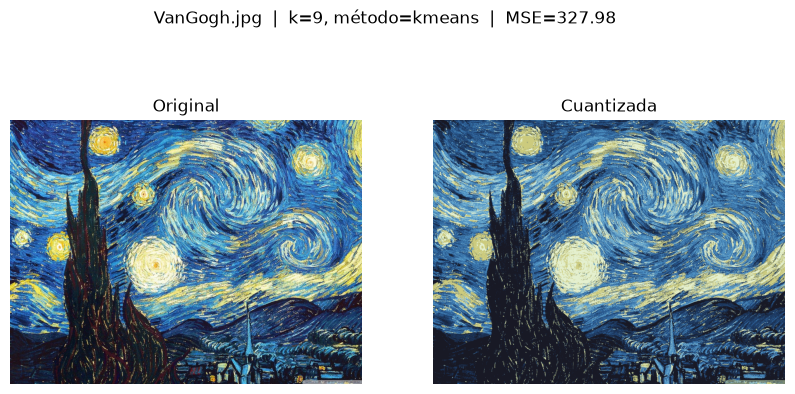

Procesando: Velazquez.jpg
MSE = 37.99


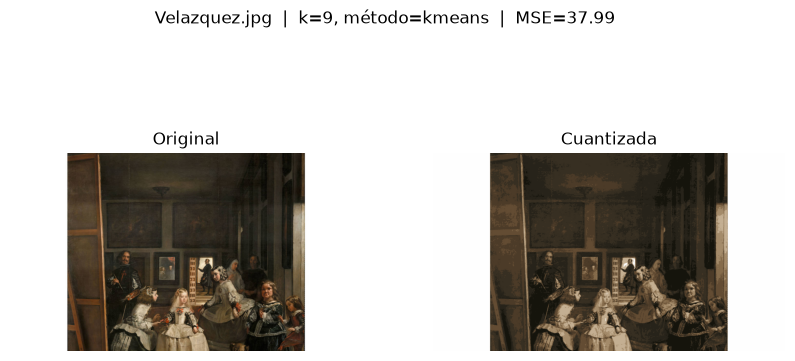

Procesando: Vermeer.jpg
MSE = 81.08


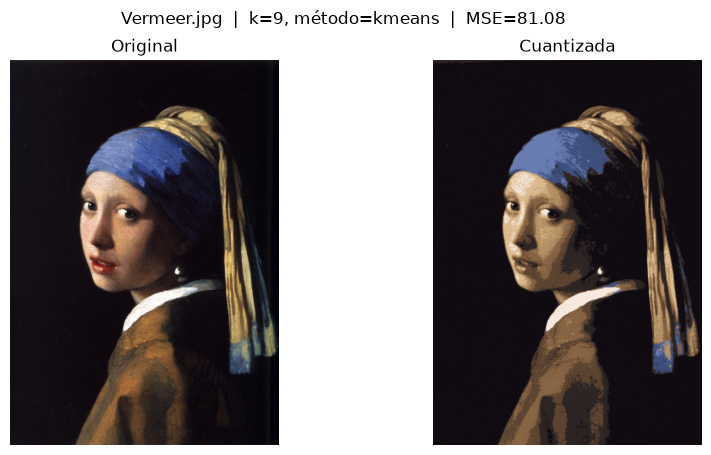


=== ERRORES (MSE) POR IMAGEN ===
Bosch.jpg: 214.95
Boticelli.jpg: 215.50
Dali.jpg: 184.19
Monet.jpg: 326.97
Picaso.jpg: 304.47
VanGogh.jpg: 327.98
Velazquez.jpg: 37.99
Vermeer.jpg: 81.08

➡ La imagen con MAYOR error es: VanGogh.jpg (MSE = 327.98)


In [46]:
resultados = {}

k = 9
metodo = "kmeans"   

for ruta in paths:
    nombre = os.path.basename(ruta)
    print(f"Procesando: {nombre}")

    img_np = np.array(Image.open(ruta)).astype(np.uint8)

    # Cuantización
    recon, mse, centers = cuantizar_exact_k(
        img_np, k=k, method=metodo, sample_size=20000, batch_size=200000
    )

    resultados[nombre] = mse
    print(f"MSE = {mse:.2f}")

    # Mostrar original y cuantizada
    plt.figure(figsize=(10,5))
    plt.suptitle(f"{nombre}  |  k={k}, método={metodo}  |  MSE={mse:.2f}")

    plt.subplot(1,2,1)
    plt.title("Original")
    plt.imshow(img_np)
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.title("Cuantizada")
    plt.imshow(recon)
    plt.axis("off")

    plt.show()

print("\n=== ERRORES (MSE) POR IMAGEN ===")
for n, e in resultados.items():
    print(f"{n}: {e:.2f}")

peor = max(resultados, key=resultados.get)
print(f"\n➡ La imagen con MAYOR error es: {peor} (MSE = {resultados[peor]:.2f})")


## Preguntas: 
### 1. ¿Está a gusto con la cuantización realizada?

En general, sí.
Las imágenes mantienen su estructura y son reconocibles aun con una paleta reducida. Se observa:

- Reducción visible de detalles finos

- Pérdida de gradientes suaves

- Áreas con colores planos más notorias

- Pero la cuantización fue eficiente considerando la restricción de máximo 15 colores.

###  2. ¿Cómo puede mejorar los resultados?

Los resultados se pueden mejorar mediante:

- **Aumentar el número de colores**

Más clusters → menos error → mejor reconstrucción.

- **Aplicar preprocesamiento**

Normalizar iluminación

Reducir ruido

Reducir resolución para acelerar pero sin perder detalle

- **Usar algoritmos especializados**

K-Medoids (robusto a outliers)

Mean Shift (encuentra colores dominantes automáticamente)

Gaussian Mixture Models (captura variancias de color)

- **Refinar K-Means**

Más iteraciones

Mayor número de inicializaciones (n_init alto)

### 3. Describa brevemente qué hacen los algoritmos de clustering y sus diferencias

- **K-Means**

Agrupa los píxeles según similitud de color.

Cada cluster está representado por un centroide (promedio).

Es rápido pero sensible a outliers.

- **Agglomerative Clustering**

Método jerárquico: empieza con cada pixel como un cluster y los va uniendo.

No depende de inicialización.

Captura mejor estructuras complejas.

Más costoso computacionalmente.

### 4. ¿Qué problemas tuvo al realizar esta parte del proyecto?

- **Errores de memoria (MemoryError)**

El principal problema fue que las imágenes tienen una gran cantidad de pixeles, y al intentar agrupar todos los pixeles al mismo tiempo, Python intentaba crear arreglos de varios cientos de millones de elementos.

- **Carga de imágenes y rutas**

Otro problema fue que:

Las imágenes no estaban en rutas absolutas correctas.

Python no encontraba archivos.

Hubo problemas al intentar cargar imágenes desde carpetas externas.

Finalmente se resolvió cargando todas las imágenes desde la misma carpeta del notebook.

- **Tiempo de procesamiento por imagen**

El proceso de:

entrenar el modelo, reconstruir la imagen completa,ncalcular el MSE, mostrar imágenes, toma tiempo, especialmente si k es alto o si se usan muchas imágenes.

Fue necesario optimizar el código para hacerlo más eficiente.

- **Diferencias entre métodos**

K-Means devuelve centroides directamente, pero el método jerárquico no.
Hubo que: calcular manualmente los colores promedio por cluster, asegurar que ningún cluster quedara vacío, convertir los colores resultantes a uint8.